<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/vision_transformers/14_Swin-UNet_Swin-Transformer-S.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains the complete training log and evaluation output for Swin-UNet_Swin-Transformer-S on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.

In [ ]:
# Install required libraries
!pip install -q timm albumentations webdataset

import os, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import matplotlib.pyplot as plt
import random
import warnings

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Swin-UNet Environment Ready! Device: {device}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 4.2 MB/s eta 0:00:00
Mounted at /content/drive
✅ Swin-UNet Environment Ready! Device: cuda


In [ ]:
drive_dataset_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/WebDataset/snow_patches_5000_random.tar"
colab_dataset_path = "/tmp/snow_patches_5000_random.tar"

os.makedirs(os.path.dirname(colab_dataset_path), exist_ok=True)
if not os.path.exists(colab_dataset_path):
    print("📥 Copying dataset to local /tmp...")
    shutil.copy(drive_dataset_path, colab_dataset_path)

print(f"✅ Dataset ready: {os.path.getsize(colab_dataset_path)/1024**3:.2f} GB")
wds_path = colab_dataset_path

📥 Copying dataset to local /tmp...
✅ Dataset ready: 0.41 GB


In [ ]:
MODEL_NAME = "SwinUNet_S_SwinSmall"
final_results_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results"
model_results_path = os.path.join(final_results_path, MODEL_NAME)

os.makedirs(model_results_path, exist_ok=True)
print(f"📁 Results Path: {model_results_path}")

📁 Results Path: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/SwinUNet_S_SwinSmall


In [ ]:
CONFIG = {
    "model_name": MODEL_NAME,
    "encoder_name": "swin_small_patch4_window7_224",
    "num_epochs": 50,
    "batch_size": 8,
    "learning_rate": 1e-4,
    "num_workers": 0,
    "total_patches": 5000,
    "img_size": 224 # Internal processing size for Swin-S
}

CONFIG["train_size"] = int(CONFIG["total_patches"] * 0.7)
CONFIG["val_size"] = int(CONFIG["total_patches"] * 0.2)
CONFIG["test_size"] = CONFIG["total_patches"] - CONFIG["train_size"] - CONFIG["val_size"]

train_batches = CONFIG["train_size"] // CONFIG["batch_size"]
val_batches = CONFIG["val_size"] // CONFIG["batch_size"]

print(f"📊 Train/Val/Test Split: {CONFIG['train_size']}/{CONFIG['val_size']}/{CONFIG['test_size']}")

📊 Train/Val/Test Split: 3500/1000/500


In [ ]:
# Swin Transformer needs 224 input, but we want to predict 256 masks
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

# Custom Preprocess to handle different Image and Mask sizes
def preprocess_sample(sample, transform):
    img = np.array(sample["image.png"].convert("RGB"))
    msk_orig = np.array(sample["mask.png"].convert("L")) / 255.0

    # 1. Apply Resize/Augmentation to Image (Targeting 224)
    t = transform(image=img)
    img_tensor = t["image"]

    # 2. Keep Mask at 256x256 (Project Requirement)
    # We apply same random seed flips manually or use a fixed resize to 256 for the mask
    msk_tensor = torch.from_numpy(msk_orig).float().unsqueeze(0)

    # Ensure mask is exactly 256x256
    if msk_tensor.shape[-1] != 256:
        msk_tensor = F.interpolate(msk_tensor.unsqueeze(0), size=(256, 256), mode='nearest').squeeze(0)

    return img_tensor, msk_tensor

print("✅ Fixed Cell 5: Mask will now stay 256x256!")

✅ Fixed Cell 5: Mask will now stay 256x256!


In [ ]:
train_dataset = (wds.WebDataset(wds_path)
    .shuffle(1000).decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG["batch_size"]))

val_dataset = (wds.WebDataset(wds_path)
    .decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG["batch_size"]))

train_loader = wds.WebLoader(train_dataset, batch_size=None).with_epoch(train_batches)
val_loader = wds.WebLoader(val_dataset, batch_size=None).with_epoch(val_batches)

print("✅ Data loaders ready!")

✅ Data loaders ready!


In [ ]:
class SwinUNet(nn.Module):
    def __init__(self, encoder_name='swin_small_patch4_window7_224', out_channels=1):
        super(SwinUNet, self).__init__()
        # Hierarchical Encoder using timm
        self.encoder = timm.create_model(encoder_name, pretrained=True, features_only=True)
        encoder_channels = self.encoder.feature_info.channels() # [96, 192, 384, 768]

        # Decoder Stages
        self.up4 = nn.ConvTranspose2d(encoder_channels[3], encoder_channels[2], 2, 2)
        self.dec4 = self._make_dec_block(encoder_channels[2] * 2, encoder_channels[2])

        self.up3 = nn.ConvTranspose2d(encoder_channels[2], encoder_channels[1], 2, 2)
        self.dec3 = self._make_dec_block(encoder_channels[1] * 2, encoder_channels[1])

        self.up2 = nn.ConvTranspose2d(encoder_channels[1], encoder_channels[0], 2, 2)
        self.dec2 = self._make_dec_block(encoder_channels[0] * 2, encoder_channels[0])

        # Final Reconstruction Head
        self.final_up = nn.ConvTranspose2d(encoder_channels[0], 64, 2, 2)
        self.final_conv = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, out_channels, 1)
        )

    def _make_dec_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        features = self.encoder(x)

        # FIXED: Permute features from [B, H, W, C] to [B, C, H, W]
        # timm Swin Transformer outputs are often channels-last
        e1 = features[0].permute(0, 3, 1, 2) # 1/4
        e2 = features[1].permute(0, 3, 1, 2) # 1/8
        e3 = features[2].permute(0, 3, 1, 2) # 1/16
        e4 = features[3].permute(0, 3, 1, 2) # 1/32

        # Decoder
        d4 = self.dec4(torch.cat([self.up4(e4), e3], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], dim=1))

        out = self.final_conv(self.final_up(d2))

        # Resize to match original patch size if needed
        return F.interpolate(out, size=(256, 256), mode='bilinear', align_corners=False)

model = SwinUNet(CONFIG["encoder_name"]).to(device)
print(f"✅ Swin-UNet Built! Params: {sum(p.numel() for p in model.parameters()):,}")

✅ Swin-UNet Built! Params: 55,657,323


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self): super().__init__(); self.bce = nn.BCEWithLogitsLoss()
    def forward(self, pred, target):
        bce = self.bce(pred, target)
        p = torch.sigmoid(pred)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + 1e-6) / (p.sum() + target.sum() + 1e-6)
        return 0.5 * bce + 0.5 * dice

def calc_metrics(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    dice = (2 * inter + 1e-6) / (pred.sum() + target.sum() + 1e-6)
    iou = (inter + 1e-6) / (union + 1e-6)
    return iou, dice

criterion = DiceBCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=5, factor=0.5)

history = {k: [] for k in ["train_loss", "val_loss", "train_iou", "val_iou", "train_dice", "val_dice", "learning_rate"]}
best_dice = 0.0

In [ ]:
def train_epoch(model, loader, num_batches):
    model.train()
    metrics = {"loss": [], "iou": [], "dice": []}
    pbar = tqdm(enumerate(loader), total=num_batches, desc="Train")
    for bi, (imgs, msks) in pbar:
        if bi >= num_batches: break
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, msks)
        loss.backward()
        optimizer.step()

        iou, dice = calc_metrics(preds, msks)
        metrics["loss"].append(loss.item())
        metrics["iou"].append(iou.item())
        metrics["dice"].append(dice.item())
        pbar.set_postfix(loss=f"{np.mean(metrics['loss']):.4f}", dice=f"{np.mean(metrics['dice']):.4f}")
    return {k: np.mean(v) for k, v in metrics.items()}

def val_epoch(model, loader, num_batches):
    model.eval()
    metrics = {"loss": [], "iou": [], "dice": []}
    with torch.no_grad():
        for bi, (imgs, msks) in enumerate(loader):
            if bi >= num_batches: break
            imgs, msks = imgs.to(device), msks.to(device)
            preds = model(imgs)
            loss = criterion(preds, msks)
            iou, dice = calc_metrics(preds, msks)
            metrics["loss"].append(loss.item())
            metrics["iou"].append(iou.item())
            metrics["dice"].append(dice.item())
    return {k: np.mean(v) for k, v in metrics.items()}

In [ ]:
print("🚀 TRAINING START")
for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['num_epochs']}")
    train_m = train_epoch(model, train_loader, train_batches)
    val_m = val_epoch(model, val_loader, val_batches)

    scheduler.step(val_m["loss"])
    lr = optimizer.param_groups[0]["lr"]

    for k in train_m.keys():
        history[f"train_{k}"].append(train_m[k])
        history[f"val_{k}"].append(val_m[k])
    history["learning_rate"].append(lr)

    if val_m["dice"] > best_dice:
        best_dice = val_m["dice"]
        torch.save(model.state_dict(), os.path.join(model_results_path, "best_model.pth"))
        print(f"  ⭐ NEW BEST: {best_dice:.4f}")

🚀 TRAINING START

Epoch 1/50


Train: 100%|██████████| 437/437 [02:08<00:00,  3.41it/s, dice=0.6192, loss=0.5003]


  ⭐ NEW BEST: 0.7051

Epoch 2/50


Train: 100%|██████████| 437/437 [02:08<00:00,  3.39it/s, dice=0.6538, loss=0.4551]


  ⭐ NEW BEST: 0.7503

Epoch 3/50


Train: 100%|██████████| 437/437 [02:09<00:00,  3.37it/s, dice=0.6658, loss=0.4376]


... (91 outputs left out)

Train: 100%|██████████| 437/437 [02:10<00:00,  3.36it/s, dice=0.8214, loss=0.2402]



Epoch 50/50


Train: 100%|██████████| 437/437 [02:09<00:00,  3.37it/s, dice=0.8225, loss=0.2397]


  ⭐ NEW BEST: 0.9315


In [ ]:
torch.save(model.state_dict(), os.path.join(model_results_path, "final_model.pth"))
pd.DataFrame(history).to_csv(os.path.join(model_results_path, "training_history.csv"), index=False)
print(f"✅ SAVED TO: {model_results_path}")

✅ SAVED TO: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/SwinUNet_S_SwinSmall


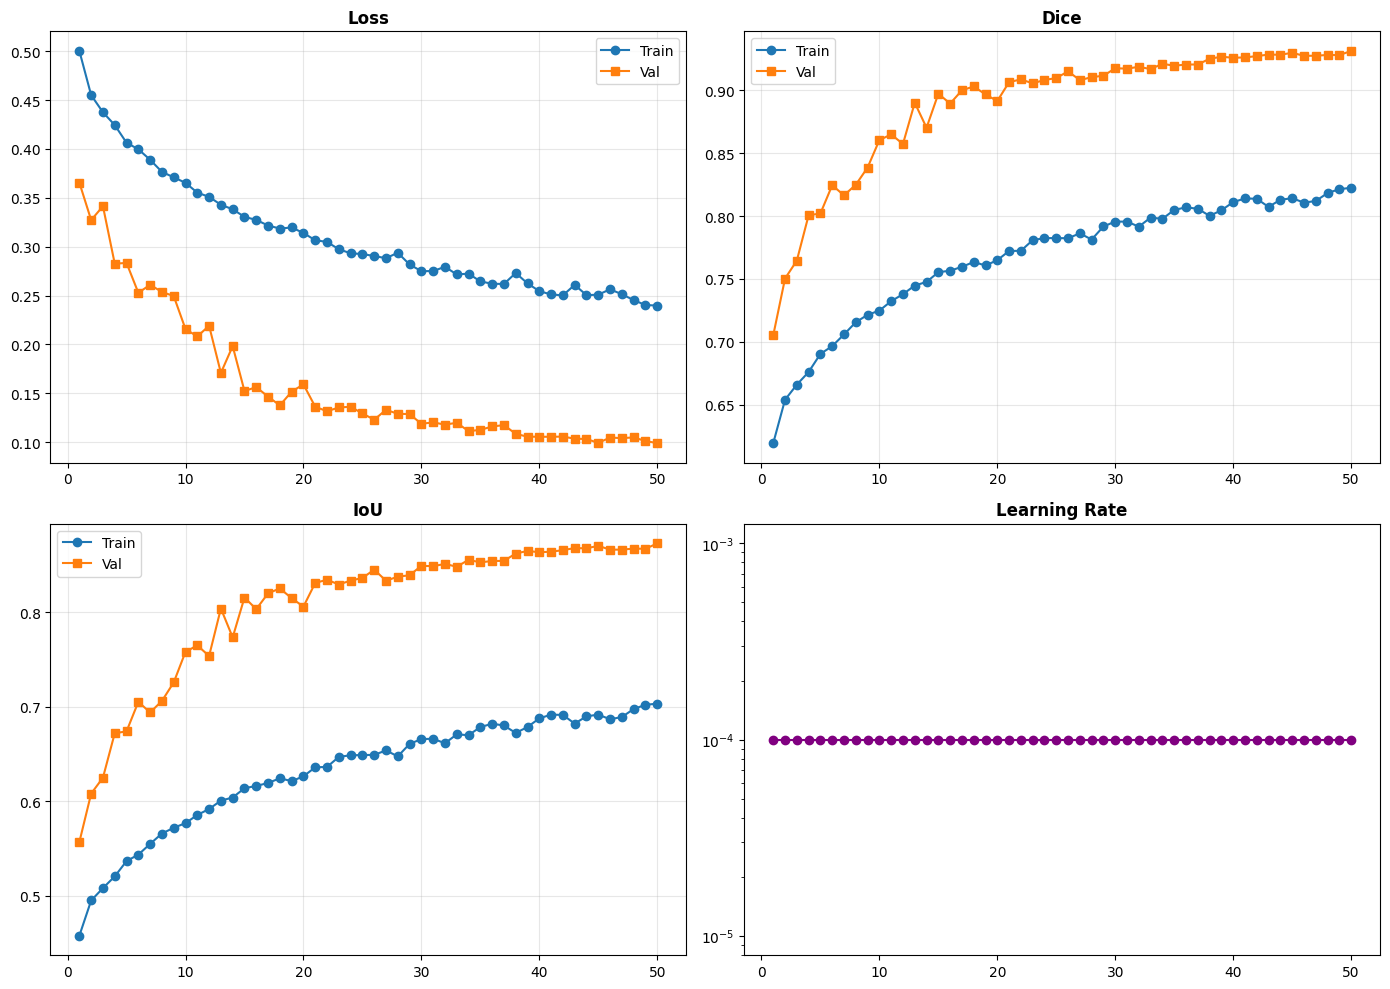

In [ ]:
epochs_range = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, (m, title) in enumerate([("loss", "Loss"), ("dice", "Dice"), ("iou", "IoU")]):
    row, col = divmod(i, 2)
    axes[row, col].plot(epochs_range, history[f"train_{m}"], "o-", label="Train")
    axes[row, col].plot(epochs_range, history[f"val_{m}"], "s-", label="Val")
    axes[row, col].set_title(title, fontweight="bold")
    axes[row, col].legend(); axes[row, col].grid(alpha=0.3)

axes[1, 1].plot(epochs_range, history["learning_rate"], "o-", color="purple")
axes[1, 1].set_title("Learning Rate", fontweight="bold"); axes[1, 1].set_yscale("log")

plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "training_curves.png"), dpi=300)
plt.show()

In [ ]:
model.load_state_dict(torch.load(os.path.join(model_results_path, "best_model.pth")))
model.eval()
raw_ds = list(wds.WebDataset(wds_path).decode("pil").to_tuple("image.png", "mask.png"))
test_indices = random.sample(range(4500, 5000), 8)

fig, axes = plt.subplots(8, 3, figsize=(15, 40))
with torch.no_grad():
    for i, idx in enumerate(test_indices):
        img_p, msk_p = raw_ds[idx]
        img_np = np.array(img_p.convert("RGB"))
        msk_np = np.array(msk_p.convert("L")) / 255.0
        img_t = val_transform(image=img_np, mask=msk_np)["image"].unsqueeze(0).to(device)
        pred = (torch.sigmoid(model(img_t)) > 0.5).squeeze().cpu().numpy()

        axes[i, 0].imshow(img_np); axes[i, 0].set_title(f"Original {idx}"); axes[i, 0].axis("off")
        axes[i, 1].imshow(msk_np, cmap='gray'); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
        axes[i, 2].imshow(pred, cmap='gray'); axes[i, 2].set_title("Prediction"); axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "viz.png"), dpi=300)
plt.show()